# PLS-aware topic orchestration for IoMT pub/sub — L1 and L2 on Colab

Upload the `pls-pubsub-iomt` folder (unzipped) to **My Drive**, then run the cells top to bottom.
Results are written to `pls-pubsub-iomt/results/` on Drive, so they survive runtime resets.

* Use a **GPU runtime** for the L2 training cells (Runtime → Change runtime type).
* Run the smoke-test cells first; they take a few minutes and confirm everything works.

In [2]:
from google.colab import drive
drive.mount('/content/drive')
import os
REPO = '/content/drive/MyDrive/pls-pubsub-iomt'
os.chdir(REPO)
!pip -q install -r requirements.txt
!python -c "import torch; print('torch', torch.__version__, 'cuda', torch.cuda.is_available())"

Mounted at /content/drive
torch 2.14.1+cu130 cuda True


## 1. Smoke test (quick mode, ~5 min)

In [2]:
!python -m l1_phy.run_l1 --quick
!python -m l2_drl.run_l2_all --quick --variants proposed agnostic --no-beta-sweep
!python figures/plot_all.py

L1 results -> /content/drive/MyDrive/pls-pubsub-iomt/results/l1/l1_20261118-103215_s0
Validation (F1-F3) ...
  F1 done (21s)
  F2 done (29s)
  F3 done (52s)
Optimal phi (F4) ...
Lookup table for L2 ...
  lookup 400/2400 (10s)
  lookup 800/2400 (21s)
  lookup 1200/2400 (32s)
  lookup 1600/2400 (44s)
  lookup 2000/2400 (57s)
  lookup 2400/2400 (70s)
Link and secrecy traces for L3 ...
  secrecy outage rate per topic/mode/phi:
phi                       0.3    0.5    0.7    0.9    1.0
topic           mode                                     
bp_glucose      single  0.000  0.000  0.000  0.000  0.213
                split   0.000  0.000  0.000  0.000  0.133
ecg_alarm       single  0.083  0.100  0.132  0.285  0.913
                split   0.005  0.003  0.010  0.078  0.882
ecg_waveform    single  0.000  0.000  0.000  0.000  0.165
                split   0.000  0.000  0.000  0.000  0.147
infusion_status single  0.025  0.015  0.022  0.060  0.602
                split   0.000  0.002  0.000  0.007 

## 2. Layer 1 — PHY secrecy experiments (full)
Writes `sop_mc.csv`, `phi_opt.csv`, `sop_lookup.csv`, `link_traces.csv`, `secrecy_traces.csv`.
For the final paper figures set `mc_trials: 1000000` in `config/params.yaml` first.

In [3]:
!python -m l1_phy.run_l1 --part validate

L1 results -> /content/drive/MyDrive/pls-pubsub-iomt/results/l1/l1_20261118-113439_s0
Validation (F1-F3) ...
  F1 done (7472s)
  F2 done (10313s)
  F3 done (18394s)
L1 done.


## 3. Layer 2 — training
Each variant × seed is an independent job (roughly 5–10 min each on GPU). If a session times out,
re-run only the missing ones with `--variants` / `--seeds`; finished runs stay on Drive.

In [3]:
!python -m l2_drl.run_l2_all --variants proposed agnostic --no-beta-sweep --no-eval

[proposed] seed 0: 400 episodes -> /content/drive/MyDrive/pls-pubsub-iomt/results/l2/train_proposed_20261119-073127_s0
  ep   20  return  -2459.3  lat  304.2 ms  miss 0.306  viol 0.567  eps 0.89  (20s)
  ep   40  return  -1937.5  lat  219.7 ms  miss 0.204  viol 0.541  eps 0.77  (46s)
  ep   60  return  -2150.0  lat  232.0 ms  miss 0.197  viol 0.507  eps 0.66  (72s)
  ep   80  return  -1642.5  lat  216.0 ms  miss 0.172  viol 0.449  eps 0.54  (98s)
  ep  100  return  -1171.7  lat  191.1 ms  miss 0.128  viol 0.383  eps 0.43  (125s)
  ep  120  return  -1134.5  lat  187.0 ms  miss 0.111  viol 0.357  eps 0.32  (152s)
  ep  140  return   -765.1  lat  166.1 ms  miss 0.074  viol 0.258  eps 0.20  (180s)
  ep  160  return   -623.2  lat  148.4 ms  miss 0.044  viol 0.306  eps 0.09  (208s)
  ep  180  return   -354.6  lat  132.9 ms  miss 0.013  viol 0.226  eps 0.05  (236s)
  ep  200  return   -586.3  lat  138.1 ms  miss 0.015  viol 0.302  eps 0.05  (264s)
  ep  220  return   -516.7  lat  144.2 ms  mi

In [4]:
!python -m l2_drl.run_l2_all --variants no_priority no_sensitivity no_sdn no_an --no-beta-sweep --no-eval

[no_priority] seed 0: 400 episodes -> /content/drive/MyDrive/pls-pubsub-iomt/results/l2/train_no_priority_20261119-091840_s0
  ep   20  return  -2373.8  lat  304.9 ms  miss 0.307  viol 0.566  eps 0.89  (19s)
  ep   40  return  -1920.8  lat  219.7 ms  miss 0.203  viol 0.544  eps 0.77  (45s)
  ep   60  return  -2112.5  lat  234.6 ms  miss 0.201  viol 0.512  eps 0.66  (72s)
  ep   80  return  -1606.4  lat  216.0 ms  miss 0.172  viol 0.454  eps 0.54  (99s)
  ep  100  return  -1142.4  lat  190.5 ms  miss 0.127  viol 0.368  eps 0.43  (126s)
  ep  120  return  -1104.0  lat  188.4 ms  miss 0.112  viol 0.329  eps 0.32  (153s)
  ep  140  return   -747.6  lat  165.3 ms  miss 0.073  viol 0.275  eps 0.20  (180s)
  ep  160  return   -613.1  lat  148.2 ms  miss 0.043  viol 0.315  eps 0.09  (207s)
  ep  180  return   -357.3  lat  132.9 ms  miss 0.012  viol 0.191  eps 0.05  (235s)
  ep  200  return   -558.8  lat  137.8 ms  miss 0.015  viol 0.294  eps 0.05  (264s)
  ep  220  return   -486.1  lat  144.4 

β_s sweep for the secrecy–latency trade-off (F9): proposed agent, seeds 0–2.

In [3]:
from common import load_params
for beta in load_params()['drl']['beta_s_grid']:
    for s in (0, 1, 2):
        !python -m l2_drl.train --variant proposed --beta-s {beta} --seed {s}

[proposed] seed 0: 400 episodes -> /content/drive/MyDrive/pls-pubsub-iomt/results/l2/train_proposed_b0_20261120-071632_s0
  ep   20  return   -294.6  lat  302.8 ms  miss 0.305  viol 0.579  eps 0.89  (20s)
  ep   40  return   -187.4  lat  220.2 ms  miss 0.207  viol 0.636  eps 0.77  (46s)
  ep   60  return   -204.3  lat  232.7 ms  miss 0.200  viol 0.624  eps 0.66  (73s)
  ep   80  return   -179.3  lat  216.8 ms  miss 0.175  viol 0.627  eps 0.54  (100s)
  ep  100  return   -145.2  lat  188.2 ms  miss 0.128  viol 0.620  eps 0.43  (128s)
  ep  120  return   -136.4  lat  185.3 ms  miss 0.111  viol 0.642  eps 0.32  (156s)
  ep  140  return   -110.6  lat  162.6 ms  miss 0.073  viol 0.594  eps 0.20  (184s)
  ep  160  return    -89.0  lat  145.4 ms  miss 0.044  viol 0.719  eps 0.09  (212s)
  ep  180  return    -73.2  lat  129.5 ms  miss 0.012  viol 0.629  eps 0.05  (240s)
  ep  200  return    -75.2  lat  134.7 ms  miss 0.014  viol 0.756  eps 0.05  (269s)
  ep  220  return    -79.7  lat  141.4 ms

## 4. Evaluation and figures

Evaluation -> /content/drive/MyDrive/pls-pubsub-iomt/results/l2/eval_20261120-094651
  proposed seed 0 done
  proposed seed 1 done
  proposed seed 2 done
  proposed seed 3 done
  proposed seed 4 done
  B1_agnostic seed 0 done
  B1_agnostic seed 1 done
  B1_agnostic seed 2 done
  B1_agnostic seed 3 done
  B1_agnostic seed 4 done
  A_no_priority seed 0 done
  A_no_priority seed 1 done
  A_no_priority seed 2 done
  A_no_priority seed 3 done
  A_no_priority seed 4 done
  A_no_sensitivity seed 0 done
  A_no_sensitivity seed 1 done
  A_no_sensitivity seed 2 done
  A_no_sensitivity seed 3 done
  A_no_sensitivity seed 4 done
  A_no_sdn seed 0 done
  A_no_sdn seed 1 done
  A_no_sdn seed 2 done
  A_no_sdn seed 3 done
  A_no_sdn seed 4 done
  A_no_an seed 0 done
  A_no_an seed 1 done
  A_no_an seed 2 done
  A_no_an seed 3 done
  A_no_an seed 4 done
  B2_fixed_an seed 0 done
  B2_fixed_an seed 1 done
  B2_fixed_an seed 2 done
  B2_fixed_an seed 3 done
  B2_fixed_an seed 4 done
  B3_crypto seed 0 d

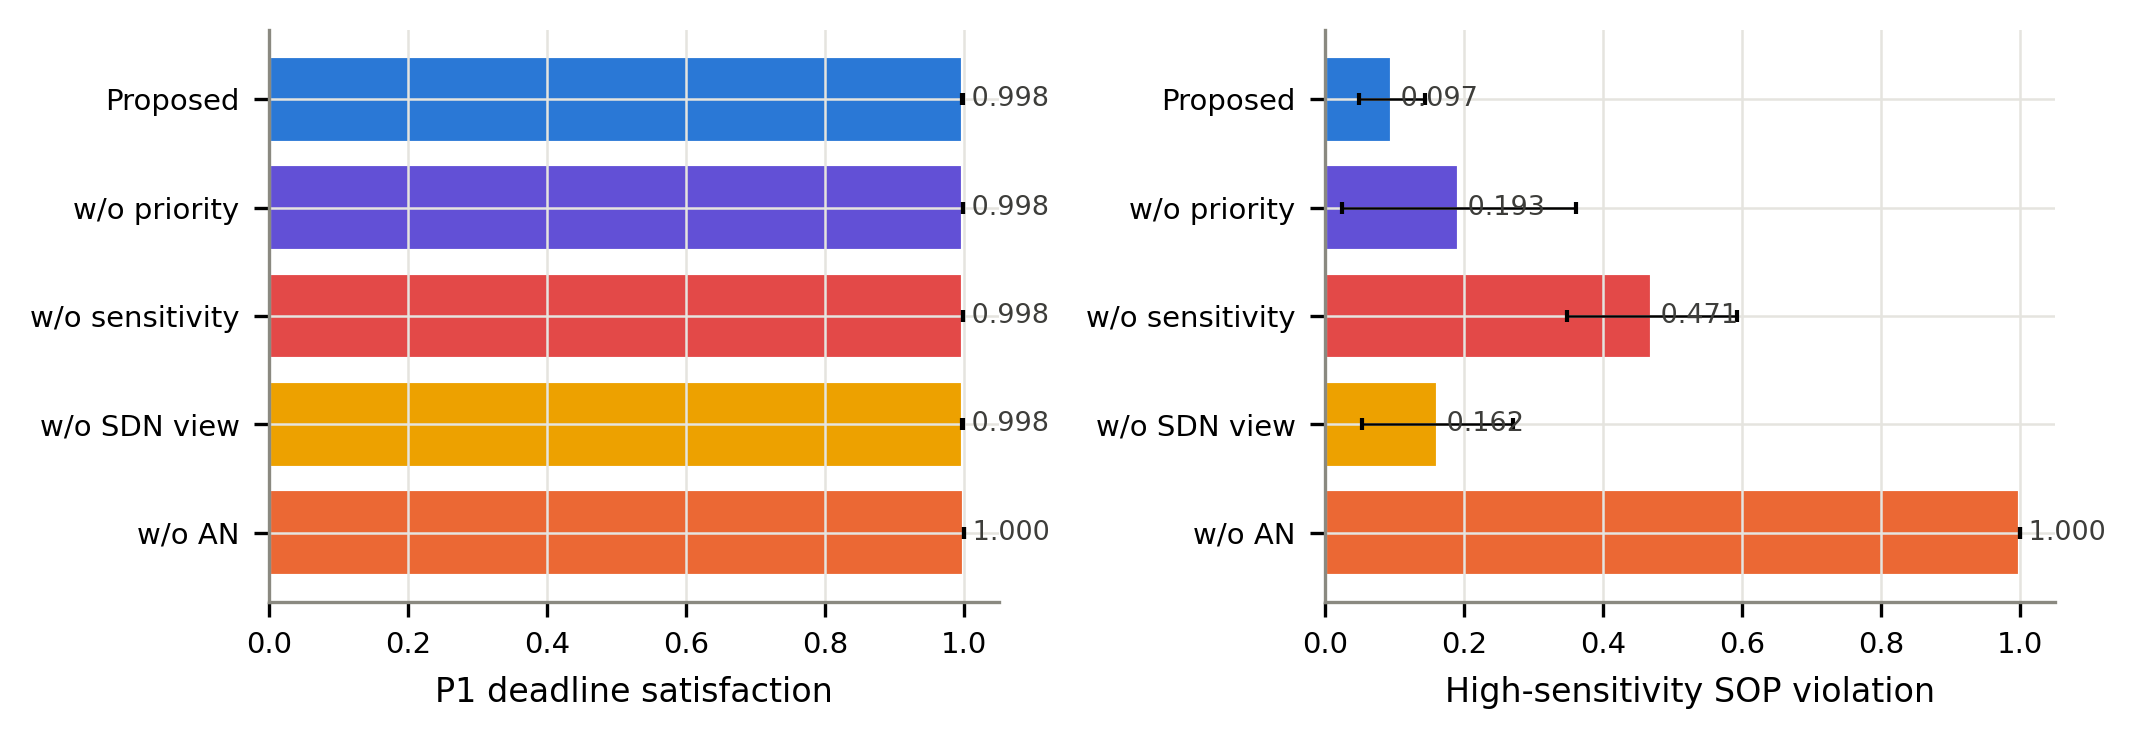

figures/F1_sop_vs_phi.png


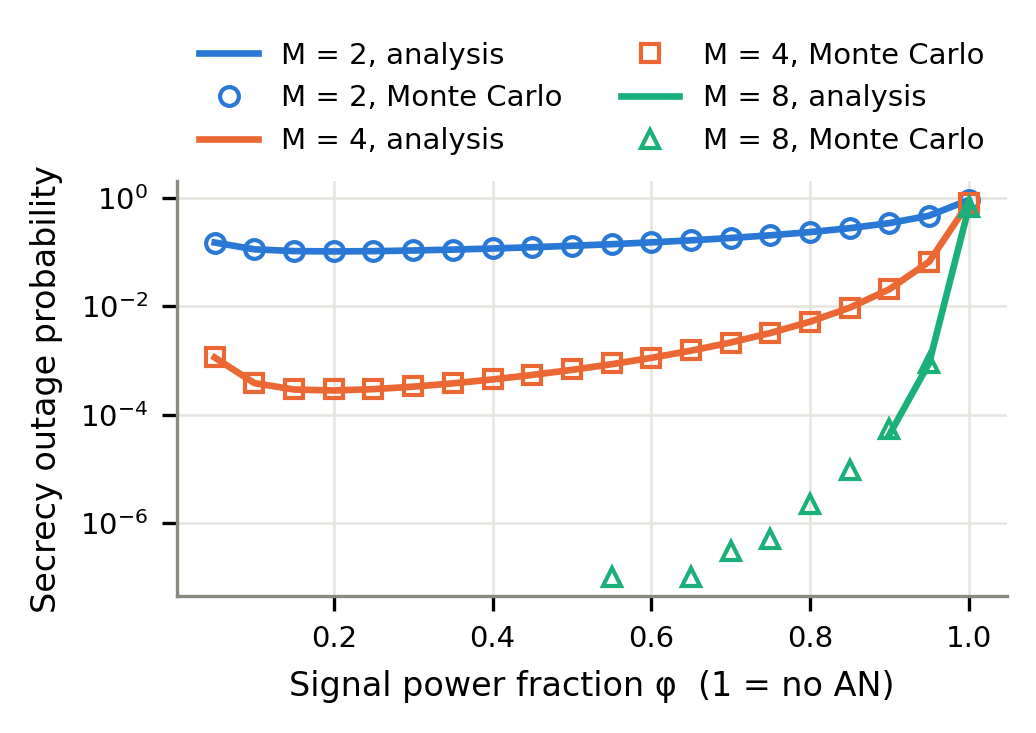

figures/F2_sop_vs_K.png


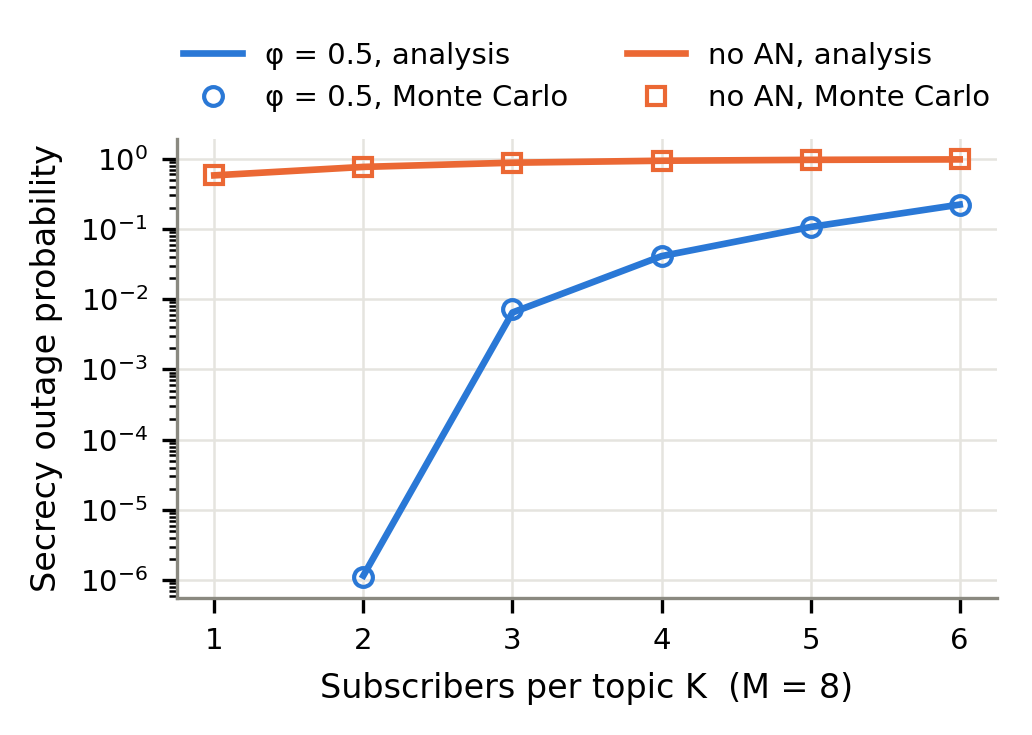

figures/F3_sop_vs_density.png


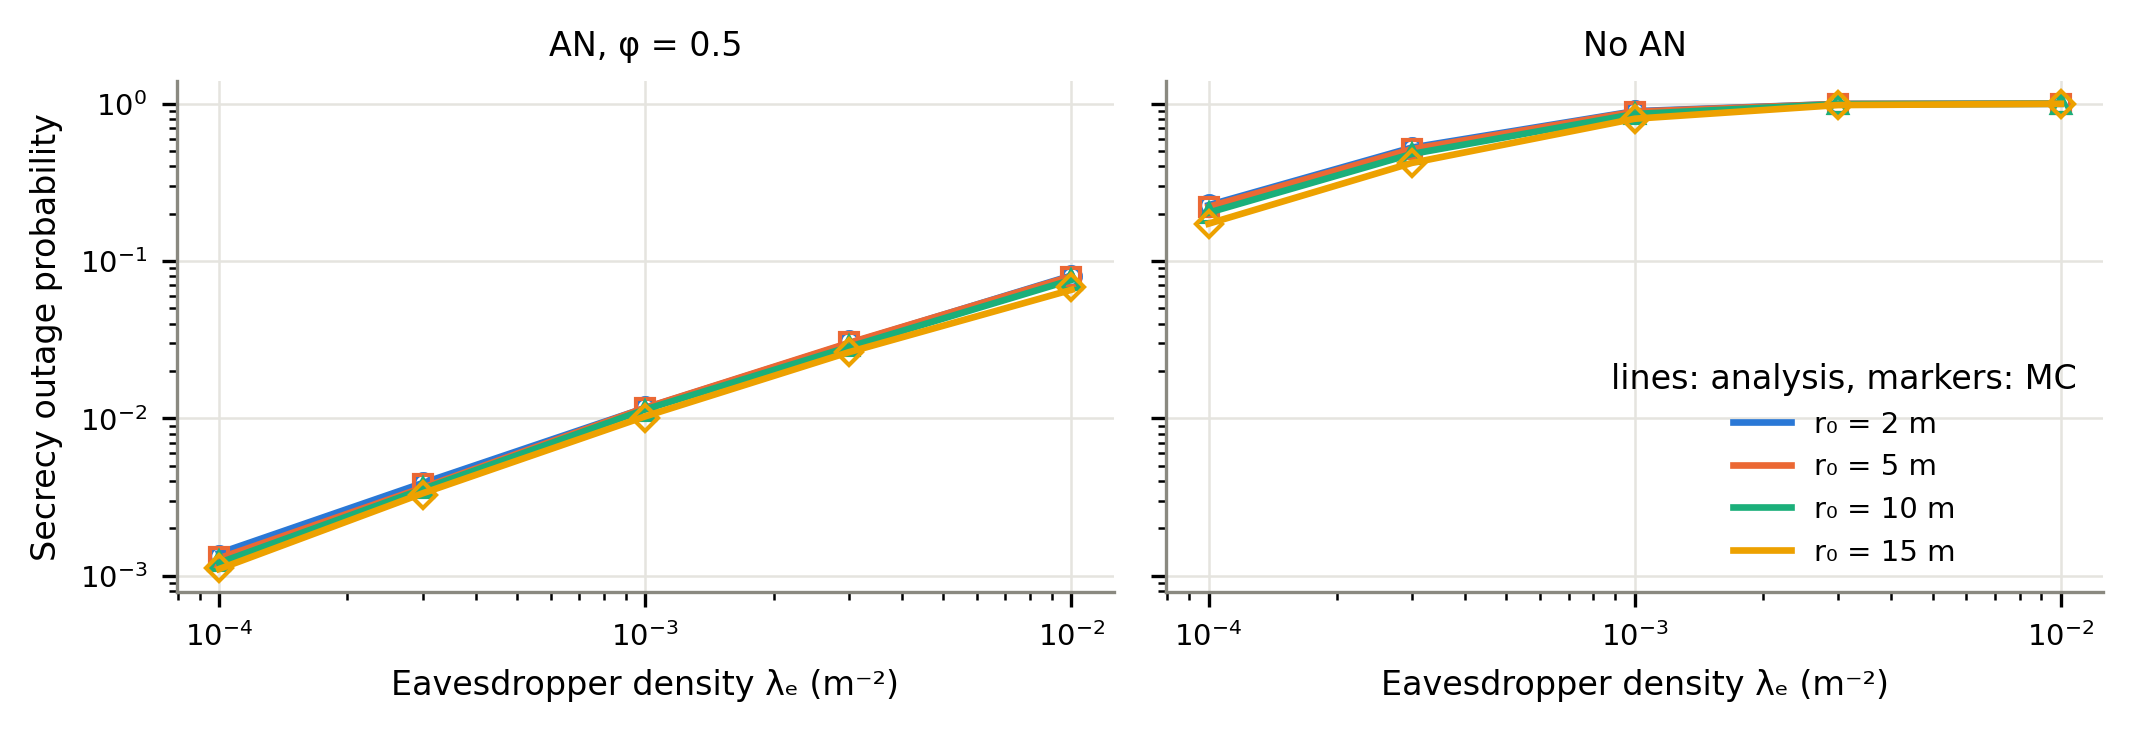

figures/F4_phi_opt.png


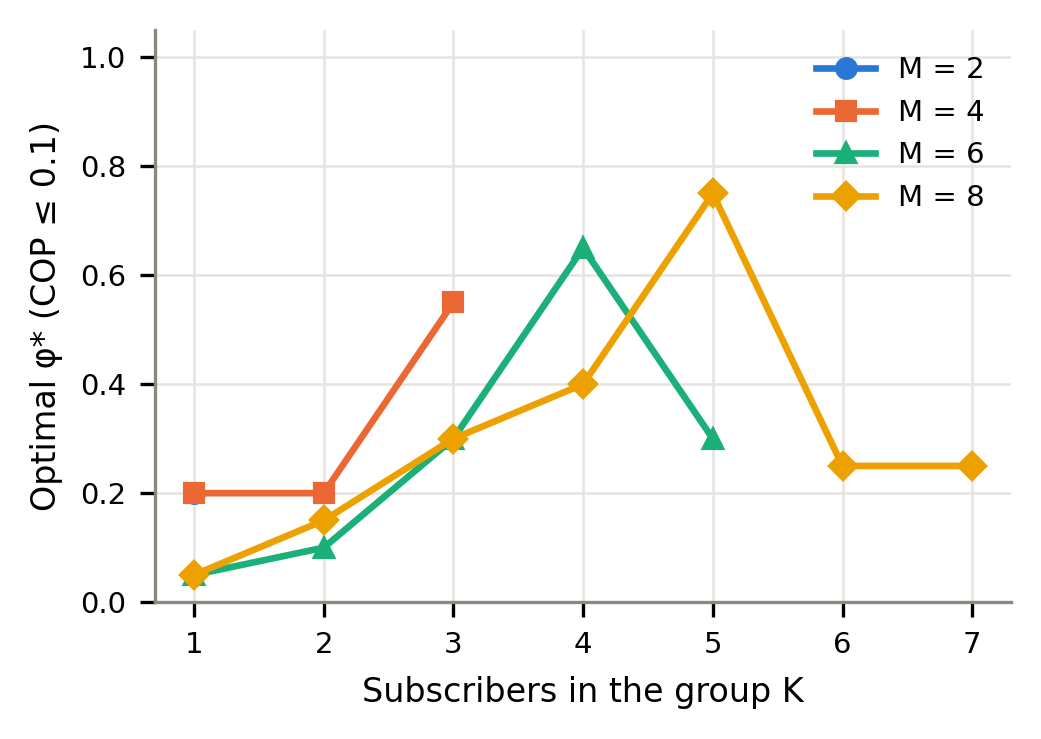

figures/F5_convergence.png


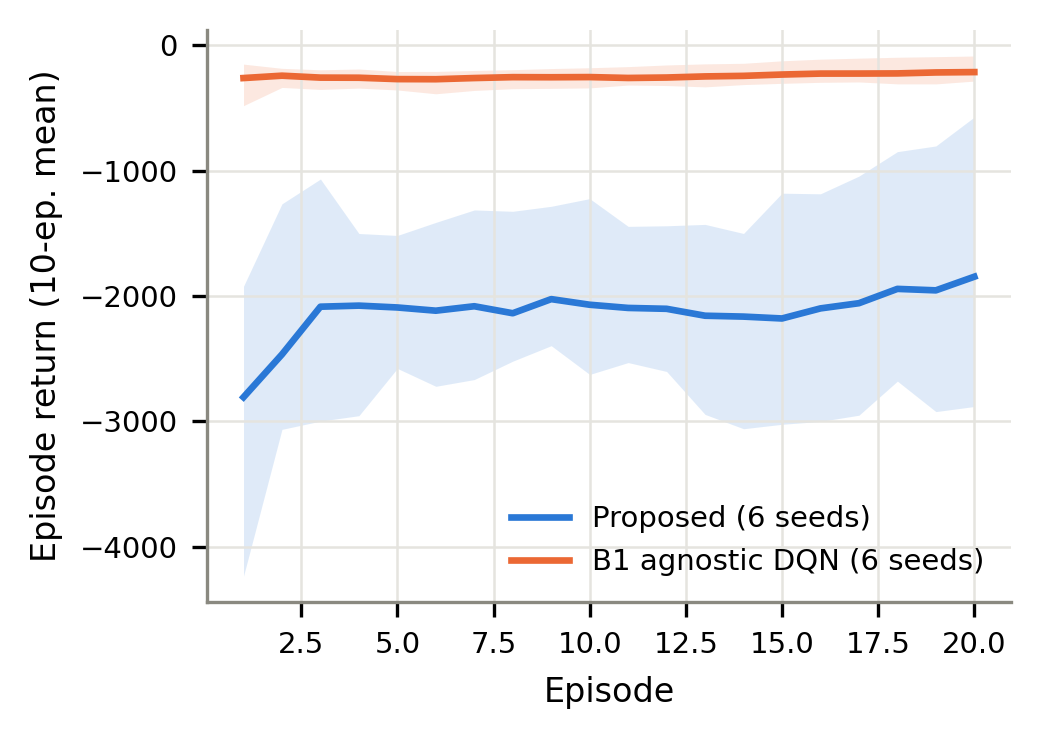

figures/F6_deadline_by_priority.png


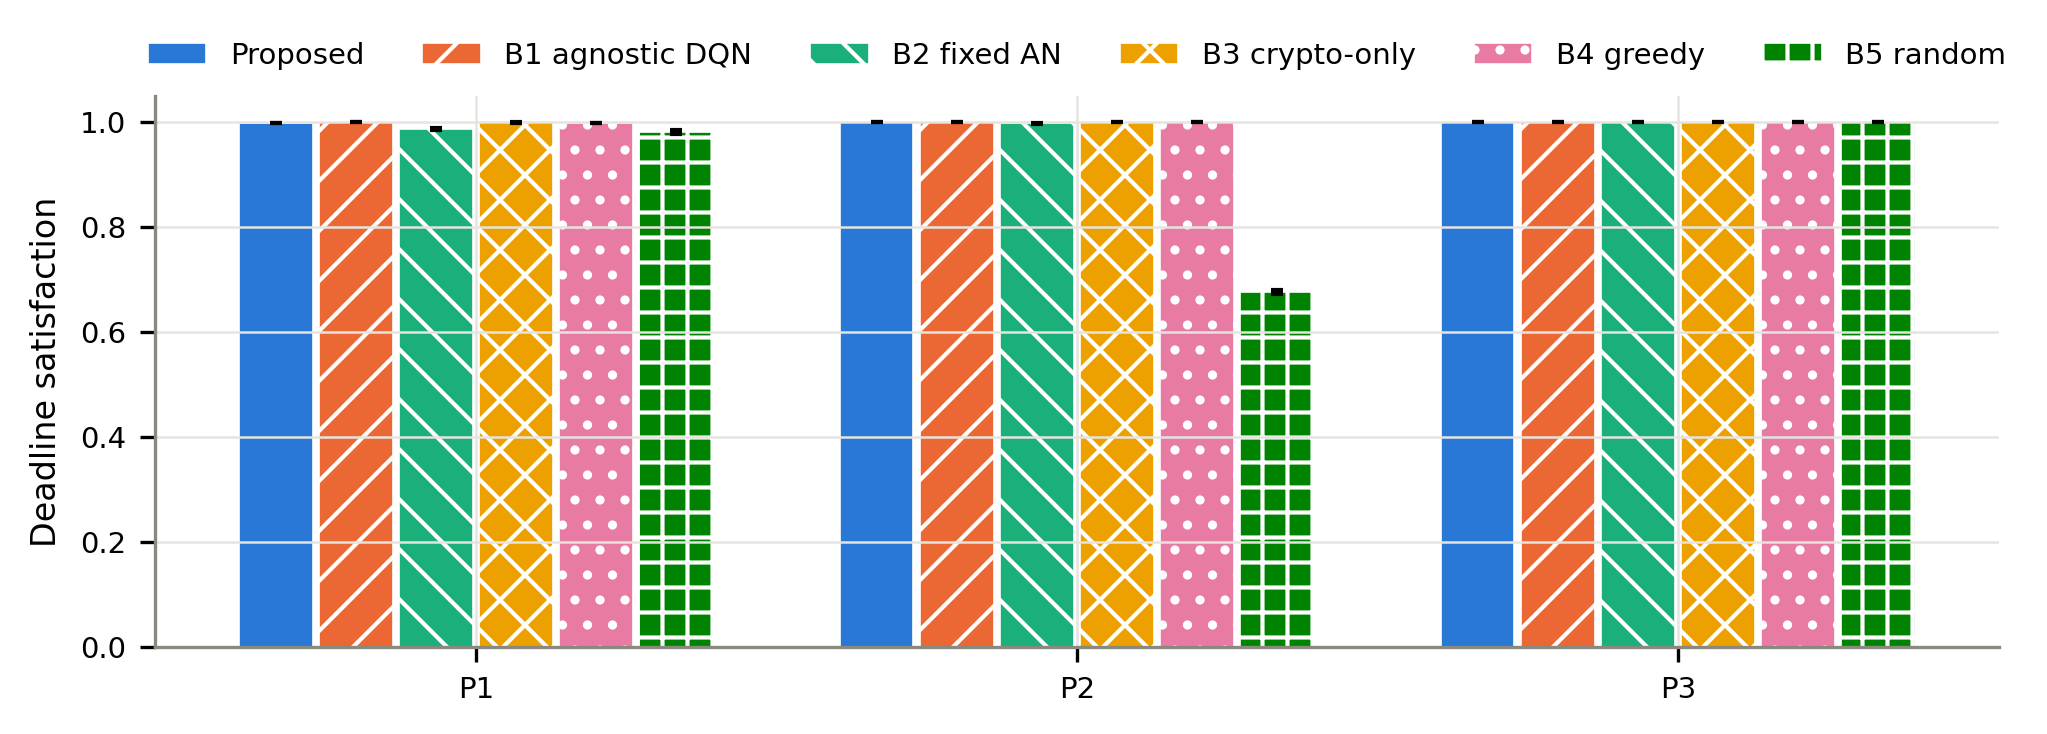

figures/F7_sop_violation_by_sensitivity.png


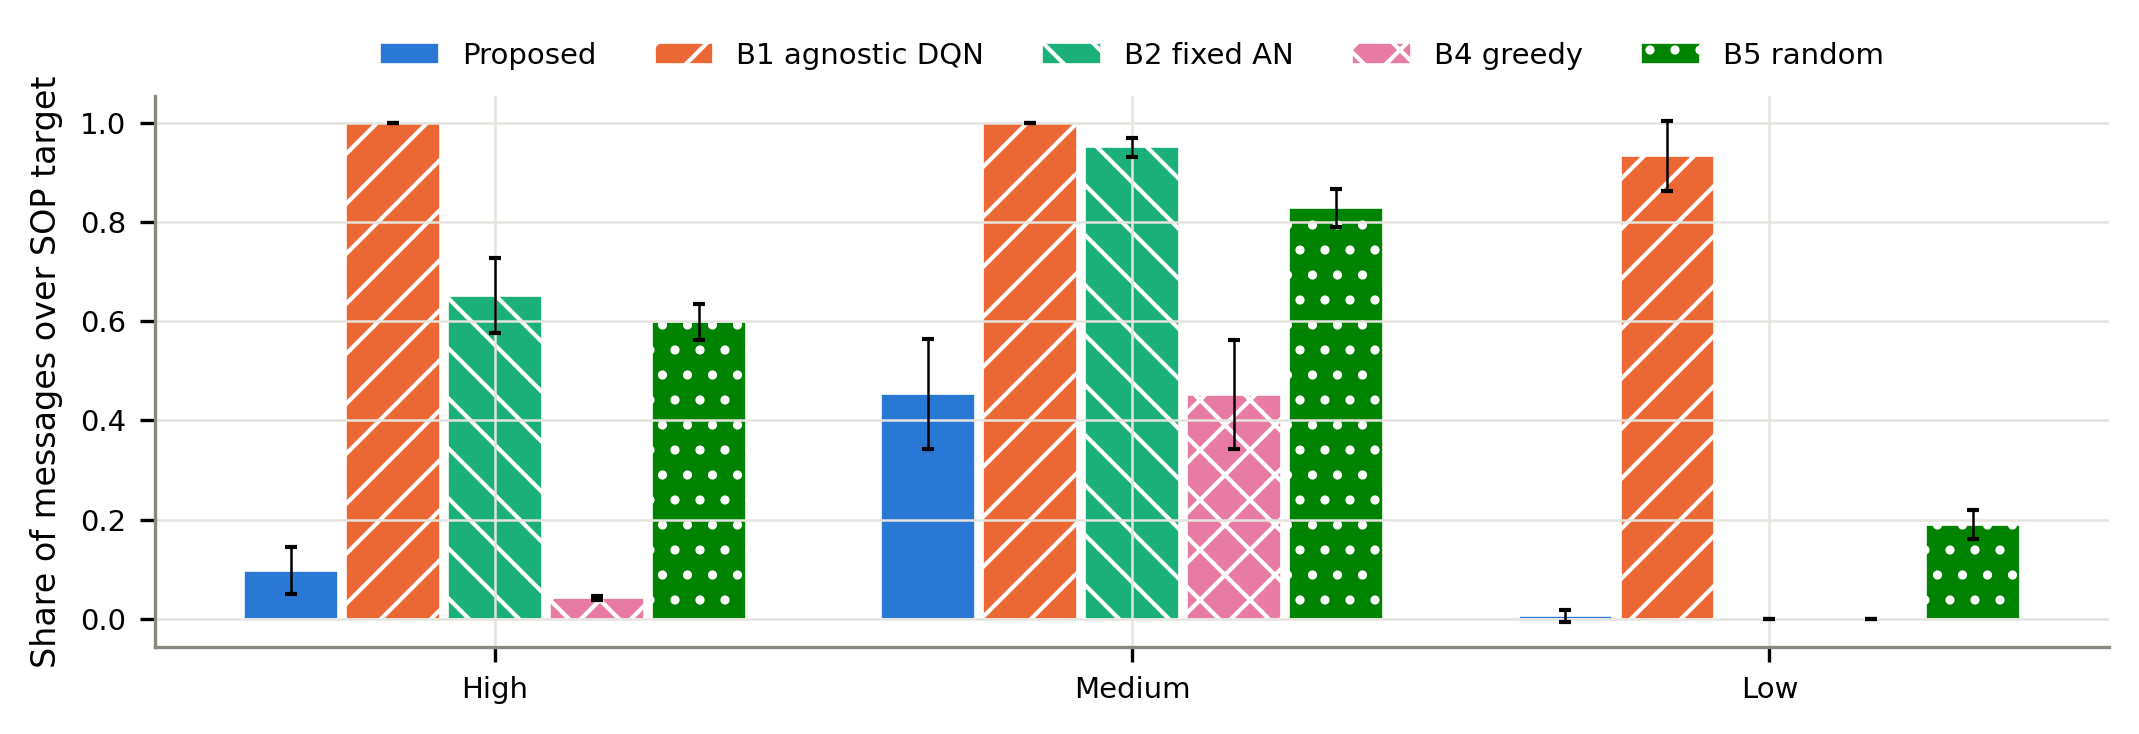

figures/F8_latency_energy_vs_load.png


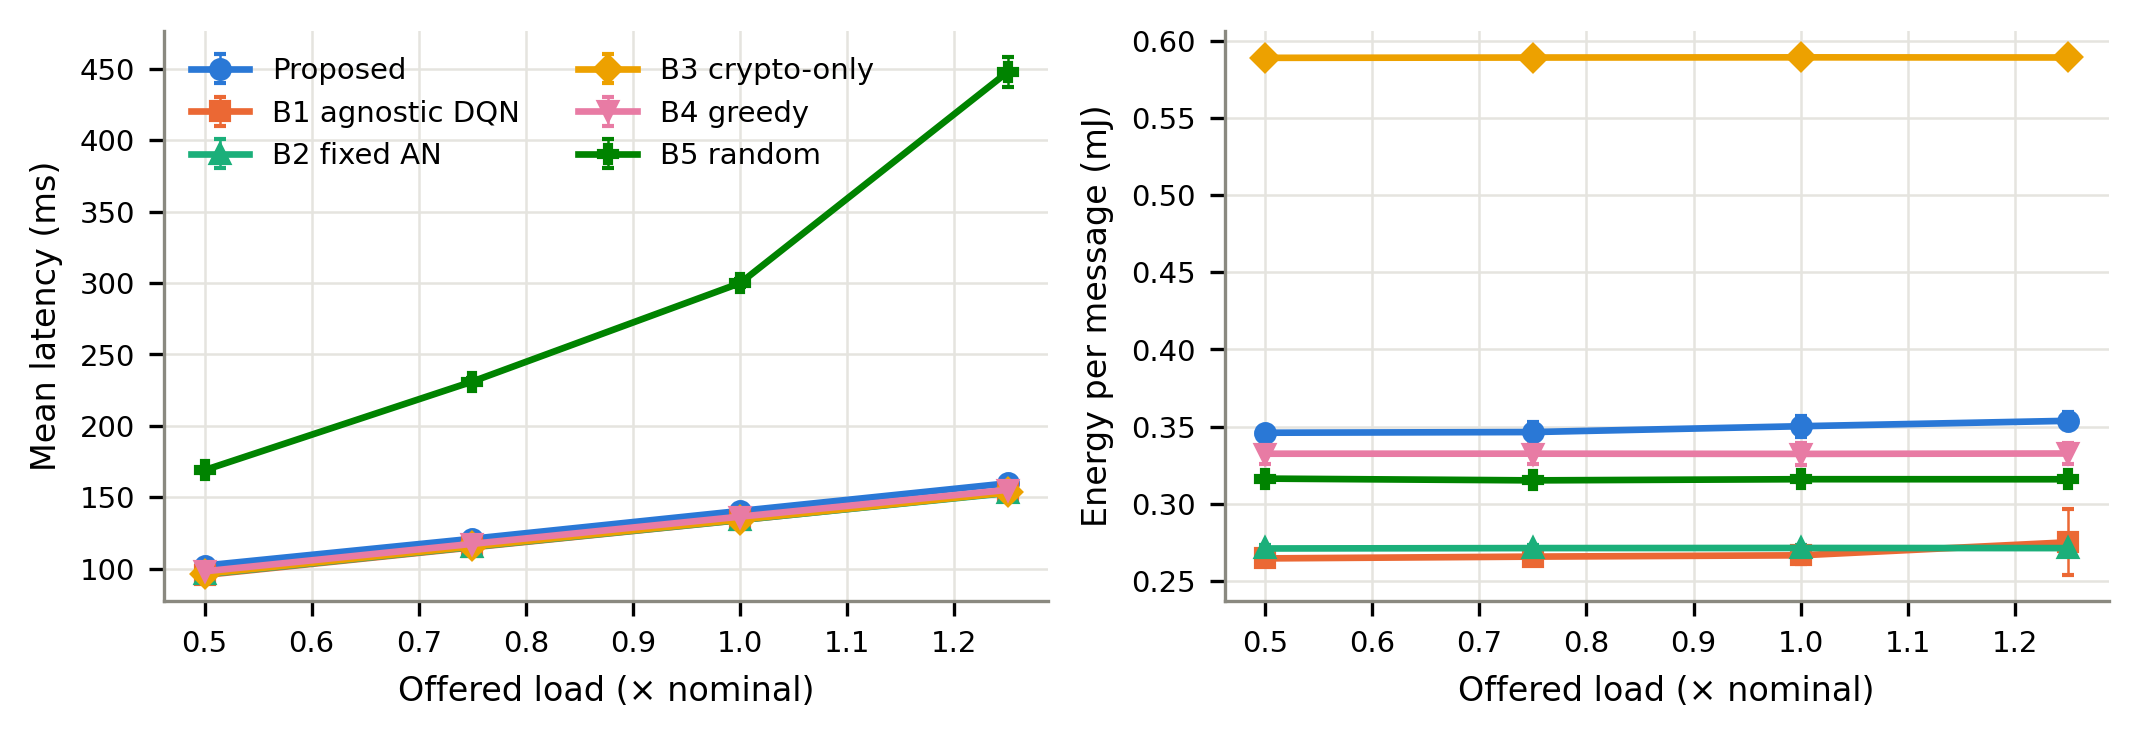

figures/F9_secrecy_latency_tradeoff.png


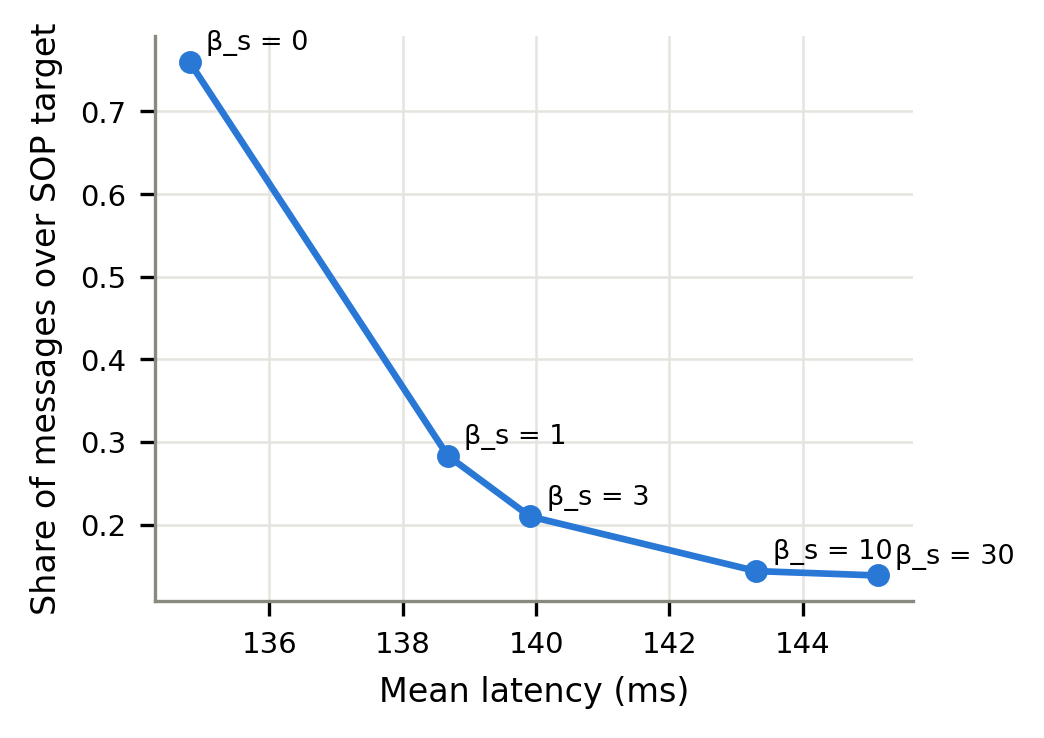

In [ ]:
!python -m l2_drl.evaluate
!python figures/plot_all.py
from IPython.display import Image, display
import glob
for f in sorted(glob.glob('figures/F*.png')):
    print(f); display(Image(f, width=600))

## 5. Hand-off to the testbed
Copy `results/l1/` and `results/l2/` from Drive into the repo on the WSL machine before running L3
(the testbed needs `link_traces.csv`, `secrecy_traces.csv`, `sop_lookup.csv` and the `policy.npz` files).